# Lab 2: Deep Learning Mini-Project: Image Quality Assessment

Authors: Alexandre Bruckert, Nantes Université

Date: 2026/2027

Over the next two lab sessions (6 hours), you will transition from learning basic PyTorch syntax to designing, optimizing, and evaluating neural networks for a real-world task.

## The task: Image Quality Assessment (IQA)

Instead of classifying what is in an image, you will predict how good it looks.
You are tackling an Image Quality Assessment (IQA) task. Your model will analyze an image and predict its Mean Opinion Score (MOS), which is a continuous value usually ranging from 1.0 (terrible quality) to 5.0 (excellent quality), representing the average human perception of the image's visual appeal, sharpness, and lack of distortions.

Because the target is a continuous number, this is a **regression** problem.

## The Dataset: KonIQ-10k
For this challenge, you will be working with the **KonIQ-10k** dataset, a major benchmark in the field of Image Quality Assessment. It consists of 10,073 images carefully sampled from a massive public multimedia database. Unlike older academic datasets where pristine images were artificially corrupted with math-generated noise, KonIQ-10k features **"in-the-wild" authentic distortions**. This means the images suffer from real-world, everyday issues: poor lighting, shaky hands (motion blur), cheap camera sensors, and aggressive JPEG compression. The ground truth MOS labels (ranging from 1.0 to 5.0) were collected through a massive crowdsourcing effort involving over 1.2 million human ratings.

The KonIQ-10k dataset is available at: https://database.mmsp-kn.de/koniq-10k-database.html
You should use the lower resolution images ($512 \times 384$) for this work.

## Evaluation

You are tasked with building the best model possible for this task. You will be evaluated based on a **heavily documented** notebook that contains your code, results, and analysis. The notebook should be structured to clearly present your approach, experiments, and findings.

Your notebook must contain the following distinct sections, representing "milestones" in the project:

- Milestone 1: The CNN Baseline: Design and train a Convolutional Neural Network (CNN) using MSELoss.

- Milestone 2: The RNN Experiment: Treat the image as a sequence of pixel rows! Design a Recurrent Neural Network (LSTM or GRU) to predict the MOS. Compare its performance to the CNN.

- Milestone 3: The Transfer Learning Approach: Use a pre-trained model (e.g., ResNet, EfficientNet) as a feature extractor. Fine-tune it for the IQA task and compare its performance to your previous models.

- Milestone 4: The Ultimate Model: Combine Early Stopping, Schedulers, Regularization, and your best architecture to build your final model.

Similarly to the grid in Lab 1, the concepts explored in each milestone will be part of the program of the final exam!

## Our way of working

Yanis DABIN and Ilef MHABRECH

We divided the project between us, with two milestones each. We created a shared Git repository and started from the same notebook. This allowed us to work separately when needed, while keeping our code in one place.

Before working on our models, we agreed on the data split, how we would evaluate predictions and how we would present training curves and results. We wanted the comparisons to remain understandable once everything was brought together. After finishing our parts, we reviewed the notebook together, compared the models and wrote the analyses jointly.

We also wanted the experiments to be easy to reproduce. We used fixed random seeds and saved selected model weights in a models folder. Yanis worked on Windows and Ilef on macOS, so we paid attention to keeping the project usable on both systems. These choices help with reproducibility, even though different hardware or software versions can still cause small differences in results.


## 0. Setup

We first load KonIQ 10k and prepare the data used by our models. The CNN and LSTM both receive RGB images resized to 128 × 128 pixels. ResNet uses a different preprocessing step later in the notebook, as it relies on pretrained ImageNet weights.

The dataset should be placed in the iqa_data folder, with the images in iqa_data/images and the labels in iqa_data/train_labels.csv.

The installation cell is optional and can remain disabled when the required packages are already available.


In [1]:
# Run this only if packages are missing, then restart the kernel
RUN_INSTALLATION = False

if RUN_INSTALLATION:
    import sys
    import shutil
    import subprocess

    pip = [sys.executable, "-m", "pip", "install"]

    if sys.platform == "win32" and shutil.which("nvidia-smi"):
        subprocess.check_call(pip + [
            "torch==2.13.0+cu130",
            "torchvision==0.28.0+cu130",
            "--extra-index-url", "https://download.pytorch.org/whl/cu130"
        ])

    subprocess.check_call(pip + ["-r", "requirements.txt"])


In [2]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset, random_split
from torchvision import transforms

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

def set_seed(seed=42):
    torch.manual_seed(seed)
    np.random.seed(seed)

set_seed(42)
print("PyTorch:", torch.__version__)
print("Device:", device)


PyTorch: 2.13.0+cu130
Device: cuda


In [3]:
# Read MOS from the CSV and load images when needed
class IQADataset(Dataset):
    def __init__(self, csv_file, img_dir, transform=None):
        """
        Args:
            csv_file (string): Path to the CSV file
                               (columns: image_name, MOS).
            img_dir (string): Directory with all the images.
            transform (callable, optional): Optional image transform.
        """
        self.labels_df = pd.read_csv(csv_file)
        self.img_dir = img_dir
        self.transform = transform

    def __len__(self):
        return len(self.labels_df)

    def __getitem__(self, idx):
        img_name = str(self.labels_df.iloc[idx]['image_name'])
        mos = float(self.labels_df.iloc[idx]['MOS'])

        img_path = os.path.join(self.img_dir, img_name)
        image = Image.open(img_path).convert('RGB')

        if self.transform:
            image = self.transform(image)

        return image, torch.tensor(mos, dtype=torch.float32)


In [4]:
# Use the same image size for CNN and LSTM
base_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

data_candidates = [Path("iqa_data"), Path("../iqa_data")]
data_dir = next(
    (p for p in data_candidates if (p / "train_labels.csv").is_file() and (p / "images").is_dir()),
    None
)
if data_dir is None:
    raise FileNotFoundError(
        "KonIQ-10k not found. Expected iqa_data/images/ and "
        "iqa_data/train_labels.csv in the current or parent directory."
    )

dataset = IQADataset(
    csv_file=data_dir / "train_labels.csv",
    img_dir=data_dir / "images",
    transform=base_transform
)

sample, label = dataset[0]
print(f"Dataset size: {len(dataset)}")
print(f"Image shape: {sample.shape}")
print(f"First MOS label: {label.item():.2f}")


Dataset size: 10073
Image shape: torch.Size([3, 128, 128])
First MOS label: 3.83


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Zoom in after the first two epochs
def plot_learning_analysis(train_losses, val_losses, best_epoch=None, title_prefix="Model", zoom_start=3):
    epochs = np.arange(1, len(train_losses) + 1)

    plt.figure(figsize=(8, 5))
    plt.plot(epochs, train_losses, marker='o', label="Training MSE")
    plt.plot(epochs, val_losses, marker='o', label="Validation MSE")

    if best_epoch is not None:
        plt.axvline(best_epoch, linestyle="--", color="gray", label=f"Best epoch: {best_epoch}")

    plt.title(f"{title_prefix} - Full Learning Curves")
    plt.xlabel("Epoch")
    plt.ylabel("MSE")
    plt.xticks(epochs)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

    if len(train_losses) >= zoom_start:
        zoom_epochs = epochs[zoom_start - 1:]
        zoom_train = train_losses[zoom_start - 1:]
        zoom_val = val_losses[zoom_start - 1:]

        plt.figure(figsize=(8, 5))
        plt.plot(zoom_epochs, zoom_train, marker='o', label="Training MSE")
        plt.plot(zoom_epochs, zoom_val, marker='o', label="Validation MSE")

        if best_epoch is not None and best_epoch >= zoom_start:
            plt.axvline(best_epoch, linestyle="--", color="gray", label=f"Best epoch: {best_epoch}")

        plt.title(f"{title_prefix} - Zoom from Epoch {zoom_start}")
        plt.xlabel("Epoch")
        plt.ylabel("MSE")
        plt.xticks(zoom_epochs)
        plt.legend()
        plt.grid(True, alpha=0.3)
        plt.show()


### 0.1. Train, validation and test split

We split the 10,073 images once using seed 42. We use 80% for training, which gives 8,058 images, 10% for validation, which gives 1,007 images, and the remaining 1,008 images for testing. All four milestones use these same image indices.

The training set is used to update the weights. The validation set helps us choose the best checkpoint and compare configurations. The test set is kept for the final evaluation of each selected model. This separation matters because choosing a model based on its test score would make that score less representative of its ability to generalize.


In [6]:
train_size = int(0.8 * len(dataset))
val_size = int(0.1 * len(dataset))
test_size = len(dataset) - train_size - val_size

# Reuse the same image indices throughout the TP
train_dataset, val_dataset, test_dataset = random_split(
    dataset,
    [train_size, val_size, test_size],
    generator=torch.Generator().manual_seed(42)
)

print(f"Training samples: {len(train_dataset)}")
print(f"Validation samples: {len(val_dataset)}")
print(f"Test samples: {len(test_dataset)}")


Training samples: 8058
Validation samples: 1007
Test samples: 1008


### 0.2. DataLoaders and batch size

We use batches of 32 images. The batch size determines how many samples contribute to a gradient estimate before the weights are updated. A larger batch generally produces a more stable estimate but requires more memory. Smaller batches need less memory, although their updates can be noisier.

We kept a batch size of 32 throughout the project. Training data is shuffled, while validation and test data are read in a fixed order. We also use fixed seeds to make the experiments more repeatable.


In [7]:
batch_size = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)


In [8]:
images, labels = next(iter(train_loader))

print("Dimensions des images :", images.shape)
print("Dimensions des labels :", labels.shape)
print("Les 5 premiers MOS :", labels[:5])


Dimensions des images : torch.Size([32, 3, 128, 128])
Dimensions des labels : torch.Size([32])
Les 5 premiers MOS : tensor([3.6881, 3.6566, 3.0917, 3.5050, 2.2477])


## 1. Milestone 1. CNN baseline

We start with a simple convolutional neural network to predict an image's Mean Opinion Score, or MOS. Since the target is a continuous value rather than a category, this is a regression task.

We use this first model to understand the training process and establish a reference for the next milestones. We also compare its predictions with a baseline that always predicts the average MOS.


### 1.1. CNN architecture

Our CNN has two convolutional layers. The first takes the three RGB channels and produces 16 feature maps. The second produces 32. These filters learn local visual information such as edges and textures, which can help when estimating image quality.

Each convolution is followed by ReLU and max pooling. ReLU allows the network to learn nonlinear relationships, while pooling reduces the size of the feature maps. Adaptive average pooling then produces one value per channel, and a final linear layer uses those 32 values to predict the MOS.

We kept the network relatively small so we could first understand how a basic CNN behaves on this task.


In [9]:
class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.regressor = nn.Linear(32, 1)

    def forward(self, x):
        x = self.features(x)
        x = torch.flatten(x, start_dim=1)
        x = self.regressor(x)
        return x.squeeze(1)

set_seed(42)
cnn_model = SimpleCNN().to(device)

print("CNN créé avec succès !")


CNN créé avec succès !


### 1.2. Loss and optimizer

We use Mean Squared Error because we want to predict a numerical score. MSE squares the difference between a prediction and the actual MOS, which means larger mistakes have a greater influence on the loss.

The optimizer is Adam with a learning rate of 0.001. After backpropagation calculates the gradients, Adam uses them to update the model's weights. A higher learning rate could make training faster but less stable. A lower one would make smaller updates and could slow down learning.

We train all the CNN layers because this model has not been pretrained. Its weights start with random values and need to learn useful visual features from our dataset. In Milestone 3, we will instead reuse weights learned on another dataset.


In [10]:
cnn_criterion = nn.MSELoss()

cnn_optimizer = optim.Adam(cnn_model.parameters(), lr=0.001)

print("Loss :", cnn_criterion)
print("Optimizer : Adam")


Loss : MSELoss()
Optimizer : Adam


### 1.3. Training and validation

We chose a budget of 20 epochs for the CNN. One epoch corresponds to a complete pass through the training data. This number is a practical choice rather than an optimal value known in advance. Too few epochs could stop learning too early, while too many could lead to overfitting or unnecessary computation.

During each epoch, the network predicts the MOS for each batch. We calculate the MSE, backpropagate the error and update the weights with Adam. At the end of the epoch, we measure the validation MSE without updating the model.

We complete the 20 epochs and keep the weights from the epoch with the lowest validation MSE. The selection is based on validation rather than test performance. Training still runs until the end, which is different from the early stopping introduced in Milestone 4.


In [11]:
import copy

epochs = 20

cnn_train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    generator=torch.Generator().manual_seed(42)
)

cnn_train_losses = []
cnn_val_losses = []

cnn_best_val_mse = float("inf")
cnn_best_epoch = 0
cnn_best_weights = None

for epoch in range(epochs):
    cnn_model.train()
    train_loss = 0.0

    for images, labels in cnn_train_loader:
        images = images.to(device)
        labels = labels.to(device)

        cnn_optimizer.zero_grad()
        predictions = cnn_model(images)
        loss = cnn_criterion(predictions, labels)

        loss.backward()
        cnn_optimizer.step()

        train_loss += loss.item() * images.size(0)

    train_loss /= len(train_dataset)
    cnn_train_losses.append(train_loss)

    cnn_model.eval()
    val_loss = 0.0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            predictions = cnn_model(images)
            loss = cnn_criterion(predictions, labels)

            val_loss += loss.item() * images.size(0)

    val_loss /= len(val_dataset)
    cnn_val_losses.append(val_loss)

    # Keep the best validation weights while training continues
    if val_loss < cnn_best_val_mse:
        cnn_best_val_mse = val_loss
        cnn_best_epoch = epoch + 1
        cnn_best_weights = copy.deepcopy(cnn_model.state_dict())

    print(
        f"Epoch {epoch+1}/{epochs} | "
        f"Train MSE: {train_loss:.4f} | "
        f"Validation MSE: {val_loss:.4f}"
    )

cnn_model.load_state_dict(cnn_best_weights)
cnn_val_mse = cnn_best_val_mse

print(f"\nBest epoch: {cnn_best_epoch}")
print(f"Best Validation MSE: {cnn_val_mse:.4f}")


Epoch 1/20 | Train MSE: 1.0391 | Validation MSE: 0.3602
Epoch 2/20 | Train MSE: 0.2819 | Validation MSE: 0.2922
Epoch 3/20 | Train MSE: 0.2351 | Validation MSE: 0.2422
Epoch 4/20 | Train MSE: 0.2278 | Validation MSE: 0.2487
Epoch 5/20 | Train MSE: 0.2261 | Validation MSE: 0.2382
Epoch 6/20 | Train MSE: 0.2256 | Validation MSE: 0.2370
Epoch 7/20 | Train MSE: 0.2264 | Validation MSE: 0.2362
Epoch 8/20 | Train MSE: 0.2202 | Validation MSE: 0.2462
Epoch 9/20 | Train MSE: 0.2196 | Validation MSE: 0.2367
Epoch 10/20 | Train MSE: 0.2178 | Validation MSE: 0.2408
Epoch 11/20 | Train MSE: 0.2244 | Validation MSE: 0.2518
Epoch 12/20 | Train MSE: 0.2176 | Validation MSE: 0.2357
Epoch 13/20 | Train MSE: 0.2208 | Validation MSE: 0.2427
Epoch 14/20 | Train MSE: 0.2168 | Validation MSE: 0.2401
Epoch 15/20 | Train MSE: 0.2193 | Validation MSE: 0.2400
Epoch 16/20 | Train MSE: 0.2173 | Validation MSE: 0.2337
Epoch 17/20 | Train MSE: 0.2150 | Validation MSE: 0.2378
Epoch 18/20 | Train MSE: 0.2171 | Valida

#### Learning curves

We plot the training and validation MSE over 20 epochs. The zoom starts at epoch 3 because the large losses at the beginning make the later changes difficult to see.


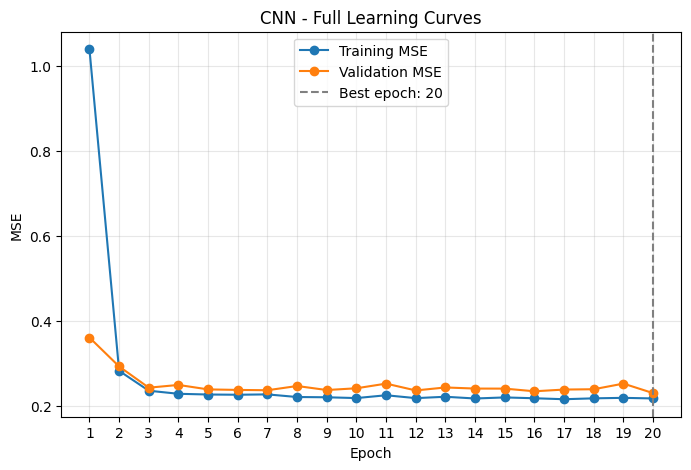

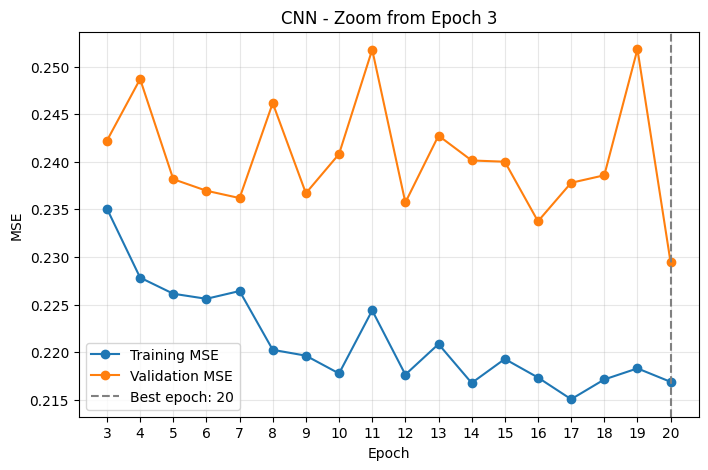

In [12]:
plot_learning_analysis(
    train_losses=cnn_train_losses,
    val_losses=cnn_val_losses,
    best_epoch=cnn_best_epoch,
    title_prefix="CNN",
    zoom_start=3
)


#### What the curves tell us

The CNN makes most of its initial progress in the first three epochs. Validation MSE falls from 0.3602 to 0.2422. After that, it moves mostly between 0.23 and 0.25 rather than decreasing steadily. The lowest value is 0.2294 at epoch 20.

Training MSE also improves, but the two curves stay fairly close. In this run, we do not see the validation error rising consistently while training error falls. We therefore cannot claim that the CNN is clearly overfitting. The main limitation is that progress becomes quite small after the initial improvement.

We chose 20 epochs as a training budget, not because we knew it was ideal. Some later epochs do not improve validation at all, even though the best checkpoint happens to be the last one. If training were much longer, we could spend more time for little benefit or begin to overfit. The early stopping strategy introduced in Milestone 4 is one way to deal with this uncertainty.


### 1.4. Looking at individual predictions

MSE summarizes the average squared error but hides how individual images are predicted. We compare ten validation predictions with their actual MOS to look for mistakes that the average score does not reveal.


In [13]:
cnn_model.eval()

images, labels = next(iter(val_loader))

images = images.to(device)

with torch.no_grad():
    predictions = cnn_model(images).cpu()

for i in range(10):
    print(
        f"Image {i+1}: "
        f"Real MOS = {labels[i].item():.2f} | "
        f"Predicted MOS = {predictions[i].item():.2f}"
    )


Image 1: Real MOS = 3.10 | Predicted MOS = 3.09
Image 2: Real MOS = 3.58 | Predicted MOS = 2.82
Image 3: Real MOS = 3.79 | Predicted MOS = 3.51
Image 4: Real MOS = 2.53 | Predicted MOS = 3.27
Image 5: Real MOS = 3.48 | Predicted MOS = 3.20
Image 6: Real MOS = 3.14 | Predicted MOS = 3.19
Image 7: Real MOS = 3.68 | Predicted MOS = 3.38
Image 8: Real MOS = 2.45 | Predicted MOS = 3.17
Image 9: Real MOS = 2.68 | Predicted MOS = 2.59
Image 10: Real MOS = 2.62 | Predicted MOS = 3.14


#### What these predictions show

Some predictions are quite close, but there are also large errors. For example, an image with a real MOS of 3.58 is predicted at 2.82, while another with a MOS of 2.53 is predicted at 3.27. Our CNN tends to give fairly central scores for several of these examples rather than separating their quality levels clearly.

Ten images are not enough to establish a general bias, but they show why an average MSE is not the whole story. If we wanted to improve this model, we could inspect more of its largest errors and test whether a richer architecture captures details that this small CNN misses.

### 1.5. Comparison with a mean baseline

To see whether the CNN is really learning from images, we compare it with a very simple reference. This baseline always predicts the average MOS of the training set, which is 3.1637, regardless of the image.

Both models are evaluated using the same validation images and the same MSE metric. If the CNN performs better, it suggests that the information it extracts from the images is useful.


In [14]:
train_indices = train_dataset.indices

train_mos = dataset.labels_df.iloc[train_indices]["MOS"]
cnn_mean_mos = train_mos.mean()

val_indices = val_dataset.indices
val_mos = dataset.labels_df.iloc[val_indices]["MOS"]

cnn_mean_baseline_mse = ((val_mos - cnn_mean_mos) ** 2).mean()

print(f"Mean training MOS: {cnn_mean_mos:.4f}")
print(f"Mean baseline Validation MSE: {cnn_mean_baseline_mse:.4f}")
print(f"CNN Validation MSE: {cnn_val_mse:.4f}")

cnn_baseline_improvement_pct = 100 * (1 - cnn_val_mse / cnn_mean_baseline_mse)
print(f"CNN vs. mean baseline improvement (validation): {cnn_baseline_improvement_pct:.1f}%")


Mean training MOS: 3.1637
Mean baseline Validation MSE: 0.3171
CNN Validation MSE: 0.2294
CNN vs. mean baseline improvement (validation): 27.6%


#### Validation comparison

We compare the CNN with a model that always predicts the mean training MOS. Both are evaluated on exactly the same validation images.


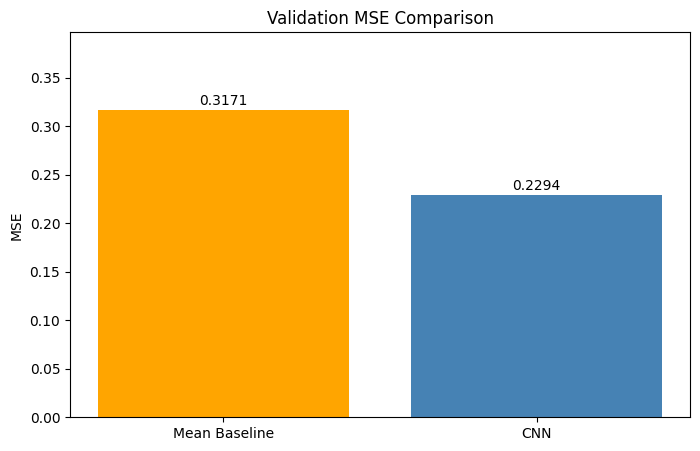

In [15]:
models = ["Mean Baseline", "CNN"]
mse_values = [cnn_mean_baseline_mse, cnn_val_mse]

plt.figure(figsize=(8, 5))
bars = plt.bar(models, mse_values, color=["orange", "steelblue"])

plt.title("Validation MSE Comparison")
plt.ylabel("MSE")

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        height + 0.005,
        f"{height:.4f}",
        ha="center"
    )

plt.ylim(0, max(mse_values) + 0.08)
plt.show()


#### What the comparison shows

The mean baseline reaches 0.3171 validation MSE, compared with 0.2294 for the CNN. This is a reduction of about 27.6% in squared error.

For our dataset, this confirms that the CNN has learned something useful from the images rather than always returning an average score. It does not mean its predictions are accurate for every image. Some individual errors remain quite large, and a more expressive network could be worth trying.


### 1.6. Test evaluation

Once we have selected the best checkpoint using validation, we evaluate it on the test images. We report MSE and RMSE. RMSE is the square root of MSE, so it is easier to relate to the scale of MOS values.

The test images are not used to choose the training epoch.


In [16]:
cnn_model.eval()

cnn_test_loss = 0.0

with torch.no_grad():
    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        predictions = cnn_model(images)

        loss = cnn_criterion(predictions, labels)

        cnn_test_loss += loss.item() * images.size(0)

cnn_test_mse = cnn_test_loss / len(test_dataset)
cnn_test_rmse = cnn_test_mse ** 0.5

print(f"Test MSE: {cnn_test_mse:.4f}")
print(f"Test RMSE: {cnn_test_rmse:.4f}")


Test MSE: 0.2085
Test RMSE: 0.4566


### 1.7. Saving the CNN

We save the selected CNN weights in the models folder. This lets us reload the trained network later without repeating the 20 epochs, provided we also have its architecture.


In [17]:
cnn_models_dir = data_dir.parent / "models"
cnn_models_dir.mkdir(parents=True, exist_ok=True)

cnn_model_path = cnn_models_dir / "cnn_baseline_20epochs.pth"
torch.save(cnn_model.state_dict(), cnn_model_path)
print(f"CNN model saved to: {cnn_model_path}")


CNN model saved to: models\cnn_baseline_20epochs.pth


### 1.8. CNN results

The following table brings together the results of this first model. The training MSE corresponds to the epoch selected using validation. In this run, that happens to be the final epoch.


In [18]:
cnn_results = pd.DataFrame({
    "Metric": [
        "Final Training MSE",
        "Final Validation MSE",
        "Mean Training MOS",
        "Mean Baseline Validation MSE",
        "Test MSE",
        "Test RMSE"
    ],
    "Value": [
        cnn_train_losses[cnn_best_epoch - 1],
        cnn_val_mse,
        cnn_mean_mos,
        cnn_mean_baseline_mse,
        cnn_test_mse,
        cnn_test_rmse
    ]
})

display(cnn_results.round(4))


,Metric,Value
0,Final Training MSE,0.2169
1,Final Validation MSE,0.2294
2,Mean Training MOS,3.1637
3,Mean Baseline Validation MSE,0.3171
4,Test MSE,0.2085
5,Test RMSE,0.4566


#### What we take away

Our CNN gives 0.2085 test MSE and 0.4566 test RMSE. It beats the constant mean baseline on validation, which makes it a useful first reference for the rest of the project.

The learning curves also highlight a limit. Training longer does not produce a steady improvement in validation, and the small network may not capture everything that contributes to perceived quality. We will compare it with a different way of processing images in the next milestone, then with pretrained visual features in Milestone 3.


## 2. Milestone 2. LSTM experiment

We now try an LSTM to predict the MOS from an image read row by row. An LSTM can carry information from one step to the next using its hidden state and cell state. Its gates decide what information to keep or update.

We want to see how this sequential representation behaves on our image quality task and compare it with the CNN. This is one experiment with a particular LSTM architecture, not a comparison of every possible recurrent model.


### 2.1. From image to sequence

Each 128 × 128 RGB image becomes a sequence of 128 rows. Every row contains 384 values because it includes 128 pixels with three color channels each. The LSTM therefore receives a sequence with 128 steps and 384 features per step.

The LSTM has 128 hidden units. We use its final hidden state to predict one MOS value through a linear layer.

Unlike the CNN, this architecture does not directly apply filters to two dimensional neighborhoods. It has to learn useful relationships between pixels through the order in which the rows are processed.


In [19]:
class LSTMRegressor(nn.Module):
    def __init__(self):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=384,
            hidden_size=128,
            num_layers=1,
            batch_first=True
        )
        self.fc = nn.Linear(128, 1)

    def forward(self, x):
        x = x.permute(0, 2, 3, 1).reshape(x.size(0), x.size(2), -1)

        _, (h_n, _) = self.lstm(x)

        return self.fc(h_n[-1]).squeeze(-1)


In [20]:
torch.manual_seed(42)
rnn_model = LSTMRegressor().to(device)

images, labels = next(iter(train_loader))
images = images.to(device)

predictions = rnn_model(images)

print("Predictions shape:", predictions.shape)
print("First predictions:", predictions[:5].detach().cpu())


Predictions shape: torch.Size([32])
First predictions: tensor([-0.0119, -0.0055, -0.0164,  0.0980,  0.0262])


### 2.2. Training configuration

We use MSE, Adam, a learning rate of 0.001 and 20 epochs, as for the CNN. Keeping the same budget makes the learning curves easier to compare, although it does not make the two architectures identical in capacity or optimization behavior.

We use validation to select the checkpoint because running all 20 epochs does not guarantee that the last one is the best.


In [21]:
rnn_criterion = nn.MSELoss()
rnn_optimizer = torch.optim.Adam(rnn_model.parameters(), lr=0.001)


#### Training and checkpoint selection

We calculate training and validation MSE after each epoch. Whenever validation improves, we save the model's weights.

The LSTM completes all 20 epochs, but its final test score comes from the best validation checkpoint rather than the last epoch.


In [22]:
rnn_models_dir = data_dir.parent / "models"
rnn_models_dir.mkdir(parents=True, exist_ok=True)
rnn_best_model_path = rnn_models_dir / "lstm_best.pth"

rnn_train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    generator=torch.Generator().manual_seed(42)
)

rnn_num_epochs = 20
rnn_train_losses = []
rnn_val_losses = []

rnn_best_val_loss = float("inf")
rnn_best_epoch = 0

for epoch in range(rnn_num_epochs):
    rnn_model.train()
    total_train_loss = 0

    for images, labels in rnn_train_loader:
        images, labels = images.to(device), labels.to(device)

        predictions = rnn_model(images)
        loss = rnn_criterion(predictions, labels)

        rnn_optimizer.zero_grad()
        loss.backward()
        rnn_optimizer.step()

        total_train_loss += loss.item() * images.size(0)

    train_loss = total_train_loss / len(rnn_train_loader.dataset)
    
    rnn_model.eval()
    total_val_loss = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)

            predictions = rnn_model(images)
            loss = rnn_criterion(predictions, labels)

            total_val_loss += loss.item() * images.size(0)

    val_loss = total_val_loss / len(val_loader.dataset)

    rnn_train_losses.append(train_loss)
    rnn_val_losses.append(val_loss)

    # Use the best validation checkpoint, not necessarily the last epoch
    if val_loss < rnn_best_val_loss:
        rnn_best_val_loss = val_loss
        rnn_best_epoch = epoch + 1
        torch.save(rnn_model.state_dict(), rnn_best_model_path)

    print(f"Epoch {epoch+1}/{rnn_num_epochs} | Train MSE: {train_loss:.4f} | Val MSE: {val_loss:.4f}")

rnn_model.load_state_dict(
    torch.load(rnn_best_model_path, map_location=device, weights_only=True)
)

print(f"\nBest epoch: {rnn_best_epoch}")
print(f"Best Validation MSE: {rnn_best_val_loss:.4f}")


Epoch 1/20 | Train MSE: 0.5444 | Val MSE: 0.2823
Epoch 2/20 | Train MSE: 0.2579 | Val MSE: 0.2700
Epoch 3/20 | Train MSE: 0.2474 | Val MSE: 0.2569
Epoch 4/20 | Train MSE: 0.2395 | Val MSE: 0.2597
Epoch 5/20 | Train MSE: 0.2383 | Val MSE: 0.2825
Epoch 6/20 | Train MSE: 0.2387 | Val MSE: 0.2570
Epoch 7/20 | Train MSE: 0.2353 | Val MSE: 0.2590
Epoch 8/20 | Train MSE: 0.2282 | Val MSE: 0.2749
Epoch 9/20 | Train MSE: 0.2234 | Val MSE: 0.2850
Epoch 10/20 | Train MSE: 0.2293 | Val MSE: 0.2651
Epoch 11/20 | Train MSE: 0.2182 | Val MSE: 0.2615
Epoch 12/20 | Train MSE: 0.2117 | Val MSE: 0.2663
Epoch 13/20 | Train MSE: 0.2082 | Val MSE: 0.2554
Epoch 14/20 | Train MSE: 0.2043 | Val MSE: 0.2600
Epoch 15/20 | Train MSE: 0.2041 | Val MSE: 0.2660
Epoch 16/20 | Train MSE: 0.2000 | Val MSE: 0.2531
Epoch 17/20 | Train MSE: 0.1944 | Val MSE: 0.2562
Epoch 18/20 | Train MSE: 0.1911 | Val MSE: 0.2638
Epoch 19/20 | Train MSE: 0.1894 | Val MSE: 0.2612
Epoch 20/20 | Train MSE: 0.1840 | Val MSE: 0.2639

Best epo

### 2.3. Learning curves

The complete view shows the overall progress. The zoom from epoch 3 lets us compare the later training and validation curves without the scale being dominated by the first epochs.


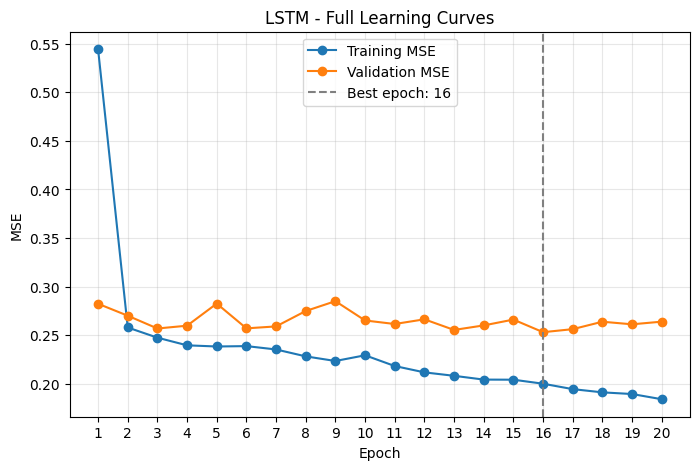

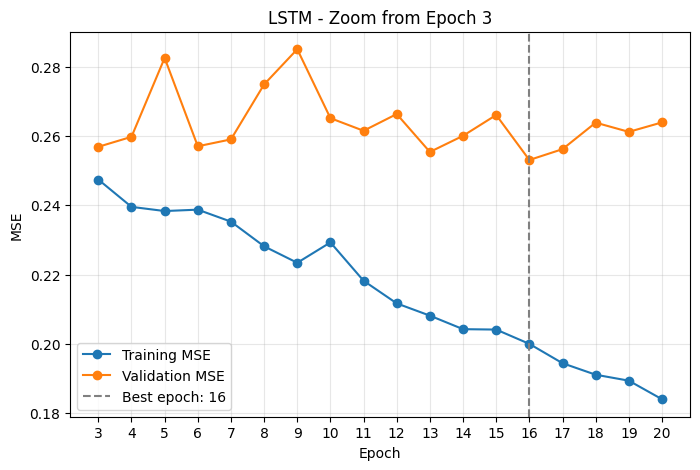

In [23]:
plot_learning_analysis(
    train_losses=rnn_train_losses,
    val_losses=rnn_val_losses,
    best_epoch=rnn_best_epoch,
    title_prefix="LSTM",
    zoom_start=3
)


#### What we observe

The training MSE decreases from 0.5444 to 0.1840 over 20 epochs. The LSTM is clearly learning to fit the training images. Validation tells a different story. It is already at 0.2569 by epoch 3 and then oscillates around 0.25 to 0.28, without improving consistently.

Epoch 16 gives the lowest validation MSE at 0.2531, so we select that checkpoint. However, epoch 6 already reached 0.2570. Training for ten more epochs only improved the best validation MSE by 0.0039, around 1.5%. Stopping around epoch 6 would therefore have been a reasonable tradeoff if we wanted to reduce computation, even though it would not give the absolute best validation score of this run.

Meanwhile, the training curve keeps falling. At epoch 16, training MSE is 0.2000. By epoch 20 it is down to 0.1840, while validation has worsened to 0.2639. The widening distance between the curves suggests that the LSTM is fitting the training set increasingly well without learning equally useful patterns for new images. This is a sign of overfitting in our experiment.

We keep the best validation checkpoint instead of the last epoch, but selecting a checkpoint does not save the computation already spent on the later epochs. In Milestone 4, early stopping will address that issue by ending training after a chosen period without improvement. Its exact stopping point will still depend on the patience setting.

#### Test evaluation

We evaluate the LSTM checkpoint chosen on validation using the same test set as the CNN. We do not select the checkpoint using these test results.


In [24]:
rnn_model.eval()
rnn_total_test_loss = 0

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)

        predictions = rnn_model(images)
        loss = rnn_criterion(predictions, labels)

        rnn_total_test_loss += loss.item() * images.size(0)

rnn_test_mse = rnn_total_test_loss / len(test_loader.dataset)

print(f"Test MSE: {rnn_test_mse:.4f}")


Test MSE: 0.2587


#### A few predictions

We also display five test images with their real and predicted MOS. This helps us see individual errors that are hidden by the average MSE.


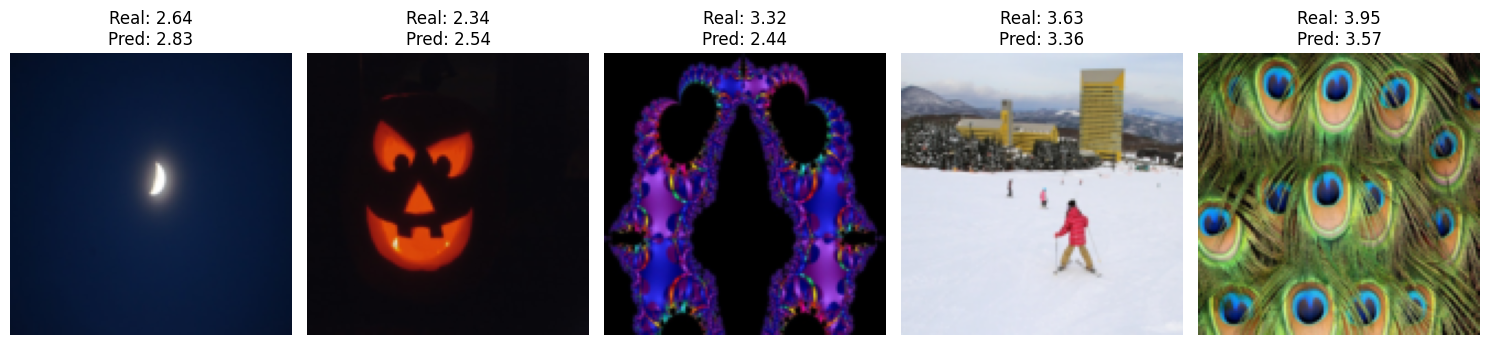

In [25]:
images, labels = next(iter(test_loader))
images, labels = images[:5], labels[:5]

rnn_model.eval()
with torch.no_grad():
    predictions = rnn_model(images.to(device)).cpu()

fig, axes = plt.subplots(1, 5, figsize=(15, 4))

for i in range(5):
    image = images[i].permute(1, 2, 0) * 0.5 + 0.5

    axes[i].imshow(image.clamp(0, 1))
    axes[i].set_title(
        f"Real: {labels[i].item():.2f}\n"
        f"Pred: {predictions[i].item():.2f}"
    )
    axes[i].axis("off")

plt.tight_layout()
plt.show()


#### What these examples show

The LSTM makes both small and large errors on these five test images. The third image is a clear example. Its real MOS is 3.32, but the model predicts 2.44. The model is therefore not equally reliable across images, even when we select the best checkpoint.

These five examples do not tell us how often this happens. The learning curves and the test MSE provide broader evidence that our particular LSTM configuration has difficulty generalizing. A different representation of the image would be worth investigating.

### 2.4. CNN versus LSTM

The table compares the two models in our experiment. They use the same data split, image size, loss and number of epochs, but different architectures.

Our CNN reaches 0.2294 validation MSE and 0.2085 test MSE. Our LSTM reaches 0.2531 and 0.2587. With the configurations we tested, the CNN therefore gives better results on this dataset.

A likely reason is the way the models process images. CNN filters look directly at nearby pixels in two dimensions, which helps preserve local structures and textures. Our LSTM instead receives one image row after another and must represent spatial relationships through its sequential state. This may make the task harder for this particular model.

We cannot conclude that LSTMs are generally worse than CNNs. A different sequence representation, recurrent architecture or set of hyperparameters could give different results. What our curves do show is that this LSTM learns the training data more easily than it improves on validation. We could explore a different representation or stronger regularization, rather than simply adding more epochs.


In [26]:
rnn_cnn_comparison = pd.DataFrame({
    "Model": ["CNN Baseline", "LSTM"],
    "Validation MSE": [cnn_val_mse, rnn_best_val_loss],
    "Test MSE": [cnn_test_mse, rnn_test_mse],
})
display(rnn_cnn_comparison.round(4))


,Model,Validation MSE,Test MSE
0,CNN Baseline,0.2294,0.2085
1,LSTM,0.2531,0.2587


## 3. Milestone 3. Transfer learning

We now use ResNet 18, a CNN that has already learned visual features from ImageNet. Instead of starting from random weights again, we reuse these features to predict image quality.

We first train a new output layer while keeping the pretrained network frozen. We then train the last ResNet block as well. These two stages let us study the difference between feature extraction and fine tuning.


### 3.1. Keeping the same data split

We keep the same image indices for training, validation and test. The inputs are not processed in exactly the same way, however. ResNet uses the image transformations associated with its pretrained weights rather than the 128 × 128 images used for the CNN and LSTM.

This means we are comparing complete approaches, including their preprocessing, rather than measuring the influence of architecture alone.


In [27]:
import copy
from torch.utils.data import Subset
from torchvision.models import resnet18, ResNet18_Weights


### 3.2. Preparing images for ResNet

We use the resizing, cropping and normalization associated with the ImageNet weights. These transformations match what the pretrained ResNet expects.

They can also affect an image quality task. Cropping might remove part of a visible defect, and resizing can change the appearance of blur or compression artifacts. We keep this preprocessing because we are reusing pretrained features, while remaining aware of this limitation when comparing results.


In [28]:
resnet_weights = ResNet18_Weights.DEFAULT
resnet_transform = resnet_weights.transforms()

# Reuse the split with the preprocessing expected by ResNet
transfer_dataset = copy.copy(dataset)
transfer_dataset.transform = resnet_transform

transfer_train = Subset(transfer_dataset, train_dataset.indices)
transfer_val = Subset(transfer_dataset, val_dataset.indices)
transfer_test = Subset(transfer_dataset, test_dataset.indices)

train_loader_tl = DataLoader(
    transfer_train,
    batch_size=32,
    shuffle=True,
    generator=torch.Generator().manual_seed(42)
)
val_loader_tl = DataLoader(transfer_val, batch_size=32, shuffle=False)
test_loader_tl = DataLoader(transfer_test, batch_size=32, shuffle=False)

print("Transfer Learning data ready!")


Transfer Learning data ready!


### 3.3. Adapting ResNet to regression

ResNet 18 originally predicts one of 1,000 ImageNet classes. We replace its final classification layer with a linear layer that takes 512 features and produces one MOS prediction.

During feature extraction, we freeze the pretrained layers. Their weights stay fixed while the new output layer learns how to use their features. ResNet also uses residual connections, which help information and gradients pass through deeper networks, as well as Batch Normalization to stabilize intermediate activations. The frozen backbone remains in evaluation mode so its BatchNorm statistics are preserved during this stage.


In [29]:
set_seed(42)

resnet_model = resnet18(weights=resnet_weights)

for param in resnet_model.parameters():
    param.requires_grad = False

resnet_model.fc = nn.Linear(resnet_model.fc.in_features, 1)

resnet_model = resnet_model.to(device)

print("ResNet18 model ready!")
print(resnet_model.fc)


ResNet18 model ready!
Linear(in_features=512, out_features=1, bias=True)


### 3.4. Loss and optimizer

We keep MSE because the task is still regression. For feature extraction, Adam only updates the new output layer, with a learning rate of 0.001.

This allows us to test whether the features learned on ImageNet are already useful for estimating image quality without changing those features.


In [30]:
resnet_criterion = nn.MSELoss()

resnet_optimizer = optim.Adam(
    resnet_model.fc.parameters(),
    lr=0.001
)


### 3.5. Feature extraction

We first train only the new output layer for five epochs, leaving the pretrained ResNet backbone frozen. This tests whether the ImageNet features can already help predict image quality.

The validation MSE reaches 0.1970 at epoch 5, better than the CNN baseline. However, it is still decreasing at the final epoch. Five epochs are therefore enough to obtain a useful first model, but not enough to demonstrate that feature extraction has converged. We keep the best checkpoint before moving to fine tuning.


In [31]:
resnet_num_epochs_fe = 5
resnet_train_losses_fe = []
resnet_val_losses_fe = []

resnet_best_val_fe = float("inf")
resnet_best_weights_fe = None

for epoch in range(resnet_num_epochs_fe):

    # Keep the frozen BatchNorm statistics unchanged
    resnet_model.eval()
    resnet_model.fc.train()

    train_loss = 0

    for images, mos in train_loader_tl:
        images = images.to(device)
        mos = mos.to(device).float().view(-1)

        resnet_optimizer.zero_grad()

        predictions = resnet_model(images).squeeze(1)
        loss = resnet_criterion(predictions, mos)

        loss.backward()
        resnet_optimizer.step()

        train_loss += loss.item() * images.size(0)

    train_mse = train_loss / len(transfer_train)
    resnet_train_losses_fe.append(train_mse)

    resnet_model.eval()
    val_loss = 0

    with torch.no_grad():
        for images, mos in val_loader_tl:
            images = images.to(device)
            mos = mos.to(device).float().view(-1)

            predictions = resnet_model(images).squeeze(1)
            loss = resnet_criterion(predictions, mos)

            val_loss += loss.item() * images.size(0)

    val_mse = val_loss / len(transfer_val)
    resnet_val_losses_fe.append(val_mse)

    if val_mse < resnet_best_val_fe:
        resnet_best_val_fe = val_mse
        resnet_best_weights_fe = copy.deepcopy(resnet_model.state_dict())

    print(f"Epoch {epoch+1}/{resnet_num_epochs_fe} | "
          f"Train MSE: {train_mse:.4f} | "
          f"Validation MSE: {val_mse:.4f}")

print(f"\nBest Feature Extraction Validation MSE: {resnet_best_val_fe:.4f}")


Epoch 1/5 | Train MSE: 0.6083 | Validation MSE: 0.3063
Epoch 2/5 | Train MSE: 0.2572 | Validation MSE: 0.2377
Epoch 3/5 | Train MSE: 0.2129 | Validation MSE: 0.2192
Epoch 4/5 | Train MSE: 0.1982 | Validation MSE: 0.2034
Epoch 5/5 | Train MSE: 0.1898 | Validation MSE: 0.1970

Best Feature Extraction Validation MSE: 0.1970


### 3.6. Fine tuning

We now train the last ResNet block, layer4, alongside the output layer. The earlier layers stay frozen because their pretrained features are already useful for recognizing basic visual patterns.

We use a learning rate of 0.00001 for layer4 and 0.0001 for fc. Layer4 contains features learned on ImageNet, so we want to adjust them carefully rather than change them too quickly. The fc layer has already learned to predict MOS during Feature Extraction, but it still needs to adapt as layer4 changes. We therefore allow larger updates in fc. The learning rate is ten times higher, although the actual size of each weight update also depends on the gradients and Adam.

We train for ten epochs and use validation MSE to select the best checkpoint. This also lets us observe whether further improvements on the training images translate to better results on validation.

Batch Normalization is active in layer4 during this phase. The earlier frozen blocks remain in evaluation mode.


In [32]:
# Start from the best feature extraction checkpoint
resnet_model.load_state_dict(resnet_best_weights_fe)

set_seed(42)

train_loader_tl = DataLoader(
    transfer_train,
    batch_size=32,
    shuffle=True,
    generator=torch.Generator().manual_seed(42)
)

for param in resnet_model.layer4.parameters():
    param.requires_grad = True

resnet_optimizer_ft = optim.Adam(
    [
        {"params": resnet_model.layer4.parameters(), "lr": 0.00001},
        {"params": resnet_model.fc.parameters(), "lr": 0.0001}
    ]
)

print("Fine-tuning ready!")


Fine-tuning ready!


In [33]:
resnet_num_epochs_ft = 10

resnet_train_losses_ft = []
resnet_val_losses_ft = []

resnet_best_val_mse = float("inf")
resnet_best_epoch = 0
resnet_best_model_weights = None

for epoch in range(resnet_num_epochs_ft):

    resnet_model.eval()
    resnet_model.layer4.train()
    resnet_model.fc.train()

    train_loss = 0

    for images, mos in train_loader_tl:
        images = images.to(device)
        mos = mos.to(device).float().view(-1)

        resnet_optimizer_ft.zero_grad()

        predictions = resnet_model(images).squeeze(1)
        loss = resnet_criterion(predictions, mos)

        loss.backward()
        resnet_optimizer_ft.step()

        train_loss += loss.item() * images.size(0)

    train_mse = train_loss / len(transfer_train)
    resnet_train_losses_ft.append(train_mse)

    resnet_model.eval()
    val_loss = 0

    with torch.no_grad():
        for images, mos in val_loader_tl:
            images = images.to(device)
            mos = mos.to(device).float().view(-1)

            predictions = resnet_model(images).squeeze(1)
            loss = resnet_criterion(predictions, mos)

            val_loss += loss.item() * images.size(0)

    val_mse = val_loss / len(transfer_val)
    resnet_val_losses_ft.append(val_mse)

    if val_mse < resnet_best_val_mse:
        resnet_best_val_mse = val_mse
        resnet_best_epoch = epoch + 1
        resnet_best_model_weights = copy.deepcopy(resnet_model.state_dict())

    print(f"Epoch {epoch+1}/{resnet_num_epochs_ft} | "
          f"Train MSE: {train_mse:.4f} | "
          f"Validation MSE: {val_mse:.4f}")

print(f"\nBest epoch: {resnet_best_epoch}")
print(f"Best Validation MSE: {resnet_best_val_mse:.4f}")


Epoch 1/10 | Train MSE: 0.1579 | Validation MSE: 0.1478
Epoch 2/10 | Train MSE: 0.1093 | Validation MSE: 0.1294
Epoch 3/10 | Train MSE: 0.0835 | Validation MSE: 0.1219
Epoch 4/10 | Train MSE: 0.0671 | Validation MSE: 0.1177
Epoch 5/10 | Train MSE: 0.0535 | Validation MSE: 0.1253
Epoch 6/10 | Train MSE: 0.0458 | Validation MSE: 0.1155
Epoch 7/10 | Train MSE: 0.0387 | Validation MSE: 0.1364
Epoch 8/10 | Train MSE: 0.0319 | Validation MSE: 0.1220
Epoch 9/10 | Train MSE: 0.0280 | Validation MSE: 0.1148
Epoch 10/10 | Train MSE: 0.0258 | Validation MSE: 0.1198

Best epoch: 9
Best Validation MSE: 0.1148


#### Comparing the two stages

These graphs show Feature Extraction and Fine-Tuning on the same vertical scale. Fine-Tuning starts from the best Feature Extraction checkpoint. We can see whether improving the fit to the training images also improves validation.


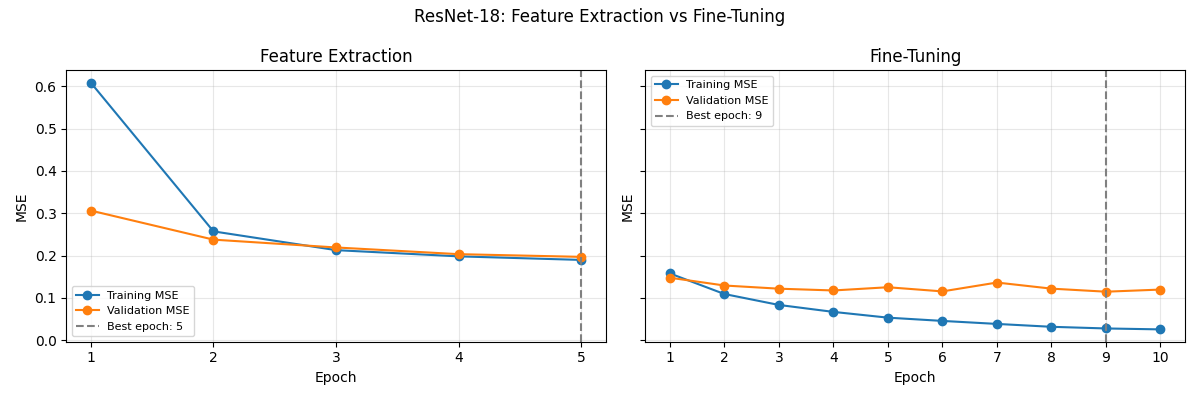

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

experiments = [
    ("Feature Extraction", resnet_train_losses_fe, resnet_val_losses_fe),
    ("Fine-Tuning", resnet_train_losses_ft, resnet_val_losses_ft)
]

for ax, (name, train_losses, val_losses) in zip(axes, experiments):
    epochs = range(1, len(train_losses) + 1)
    best_epoch = np.argmin(val_losses) + 1

    ax.plot(epochs, train_losses, marker="o", label="Training MSE")
    ax.plot(epochs, val_losses, marker="o", label="Validation MSE")
    ax.axvline(
        best_epoch, color="gray", linestyle="--",
        label=f"Best epoch: {best_epoch}"
    )

    ax.set_title(name)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("MSE")
    ax.set_xticks(list(epochs))
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

plt.suptitle("ResNet-18: Feature Extraction vs Fine-Tuning")
plt.tight_layout()
plt.show()


#### What the curves tell us

During Feature Extraction, training and validation MSE both decrease over the five epochs. The validation score is best at epoch 5 with 0.1970. Since the curve is still improving at that point, a longer feature extraction experiment might have helped. We did not test that possibility here.

Fine-Tuning brings validation MSE down to 0.1148 at epoch 9. This is a substantial improvement over the Feature Extraction result. Training MSE, however, continues falling almost every epoch, from 0.1579 to 0.0258. Validation varies much more and even rises to 0.1364 at epoch 7. At epoch 10, it rises again to 0.1198 despite the lowest training MSE of the run.

This is a warning sign of overfitting. Adapting layer4 makes the model fit our training images very well, but that progress is not equally consistent on validation. We therefore keep the epoch 9 checkpoint instead of the final epoch.

A longer budget alone would not solve this issue. We could try early stopping or more regularization, which is precisely what we explore in Milestone 4. We should also remember that Feature Extraction lasted five epochs and Fine-Tuning lasted ten. Their score difference cannot be attributed entirely to unfreezing layer4 without a more controlled comparison.

### 3.7. Saving the model

We restore the weights from the epoch with the lowest validation MSE and save them in the models folder. As in the previous milestones, the checkpoint is selected without using the test results.


In [35]:
resnet_model.load_state_dict(resnet_best_model_weights)
resnet_model.eval()

resnet_models_dir = data_dir.parent / "models"
resnet_models_dir.mkdir(parents=True, exist_ok=True)

resnet_model_path = resnet_models_dir / "resnet18_finetuning_10epochs_best.pth"

torch.save(resnet_model.state_dict(), resnet_model_path)

print(f"Model saved to: {resnet_model_path}")


Model saved to: models\resnet18_finetuning_10epochs_best.pth


### 3.8. Test evaluation

We evaluate the selected fine tuned model on the test images. MSE measures its average squared prediction error, while RMSE expresses the error on the MOS scale.


In [36]:
resnet_model.eval()
resnet_test_loss = 0

with torch.no_grad():
    for images, mos in test_loader_tl:
        images = images.to(device)
        mos = mos.to(device).float().view(-1)

        predictions = resnet_model(images).squeeze(1)

        loss = resnet_criterion(predictions, mos)
        resnet_test_loss += loss.item() * images.size(0)

resnet_test_mse = resnet_test_loss / len(transfer_test)
resnet_test_rmse = resnet_test_mse ** 0.5

print(f"Test MSE: {resnet_test_mse:.4f}")
print(f"Test RMSE: {resnet_test_rmse:.4f}")


Test MSE: 0.1187
Test RMSE: 0.3445


### 3.9. Comparing the approaches

The graphs below compare our CNN baseline, Feature Extraction and Fine-Tuning. A lower MSE means a smaller average squared prediction error. Both graphs use the same vertical scale so that their values can be compared visually.

Feature Extraction does not have a test score because it is an intermediate stage of Milestone 3. We selected its best checkpoint using validation and then continued with Fine-Tuning. We evaluated the resulting Fine-Tuning model on the test set. The CNN and LSTM were also tested as the final models of their respective milestones.

ResNet uses pretrained weights and different image preprocessing from the earlier models. We can compare the results of the approaches we implemented, but we cannot attribute the entire difference to architecture alone.


,Model,Validation MSE,Test MSE
0,CNN Baseline,0.2294,0.2085
1,Feature Extraction,0.1970,NaN
2,Fine-Tuning,0.1148,0.1187


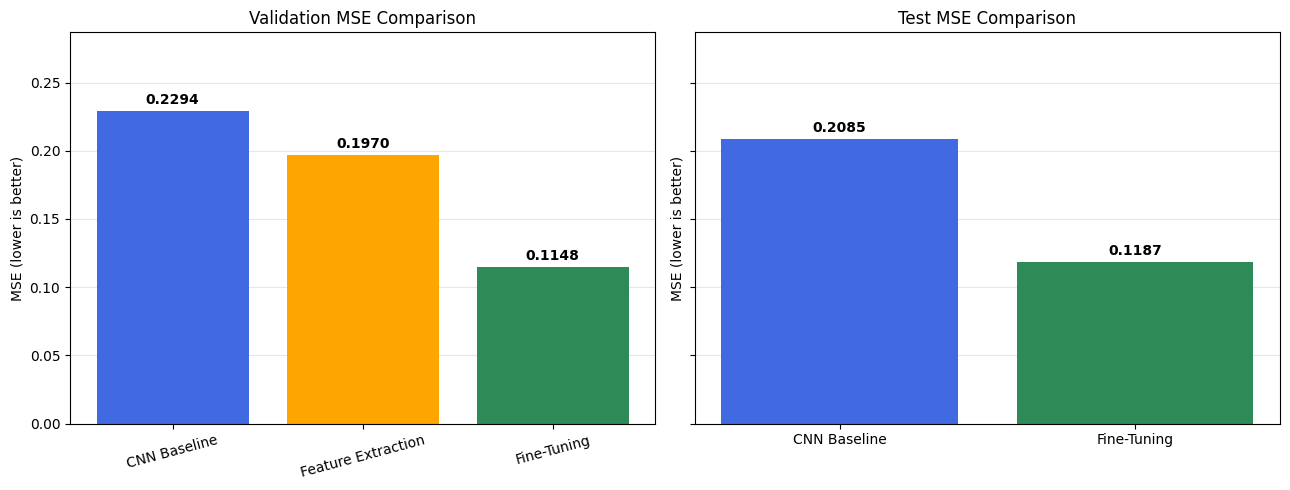

In [37]:
resnet_feature_val_mse = min(resnet_val_losses_fe)
resnet_finetuning_val_mse = resnet_best_val_mse

resnet_comparison = pd.DataFrame({
    "Model": [
        "CNN Baseline",
        "Feature Extraction",
        "Fine-Tuning"
    ],
    "Validation MSE": [
        cnn_val_mse,
        resnet_feature_val_mse,
        resnet_finetuning_val_mse
    ],
    "Test MSE": [
        cnn_test_mse,
        None,
        resnet_test_mse
    ]
})

display(resnet_comparison.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)

axes[0].bar(
    resnet_comparison["Model"],
    resnet_comparison["Validation MSE"],
    color=["royalblue", "orange", "seagreen"]
)

axes[0].set_title("Validation MSE Comparison")
axes[0].set_ylabel("MSE (lower is better)")
axes[0].tick_params(axis="x", rotation=15)

resnet_test_models = ["CNN Baseline", "Fine-Tuning"]
resnet_test_values = [cnn_test_mse, resnet_test_mse]

axes[1].bar(
    resnet_test_models,
    resnet_test_values,
    color=["royalblue", "seagreen"]
)

axes[1].set_title("Test MSE Comparison")
axes[1].set_ylabel("MSE (lower is better)")

for ax in axes:
    for bar in ax.patches:
        value = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            value + 0.005,
            f"{value:.4f}",
            ha="center",
            fontweight="bold"
        )

    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)

shared_max = max(resnet_comparison["Validation MSE"].max(), max(resnet_test_values))
axes[0].set_ylim(0, shared_max * 1.25)

plt.tight_layout()
plt.show()


### 3.10. What the comparison shows

On validation, Feature Extraction reaches 0.1970 compared with 0.2294 for the CNN. Fine-Tuning improves further to 0.1148. On test, our fine tuned ResNet reaches 0.1187 MSE, compared with 0.2085 for the CNN.

In our experiments, reusing pretrained visual features and adapting the final ResNet block gave the strongest results so far. One plausible explanation is that the pretrained network starts with useful visual representations, so it does not have to learn everything from the KonIQ images alone.

This comparison has limits. The models do not share the same architecture or image preprocessing, and the two ResNet training stages use different epoch budgets. We can report the improvement we measured, but we cannot assign all of it to one specific choice. The learning curves above also show why better validation checkpoints matter when training starts to fit the training set too closely.


### 3.11. Results from the first three milestones

The table brings together our validation and test MSE values. Each validation score comes from the best checkpoint for that model. We did not run a separate test evaluation for Feature Extraction because it was an intermediate stage before Fine-Tuning.


In [38]:
unified_results = pd.DataFrame({
    "Model": ["CNN Baseline", "LSTM", "ResNet-18 Feature Extraction", "ResNet-18 Fine-Tuning"],
    "Validation MSE": [cnn_val_mse, rnn_best_val_loss, resnet_best_val_fe, resnet_best_val_mse],
    "Test MSE": [cnn_test_mse, rnn_test_mse, float("nan"), resnet_test_mse],
    "Test RMSE": [cnn_test_rmse, rnn_test_mse ** 0.5, float("nan"), resnet_test_rmse],
})
display(unified_results.round(4))


,Model,Validation MSE,Test MSE,Test RMSE
0,CNN Baseline,0.2294,0.2085,0.4566
1,LSTM,0.2531,0.2587,0.5087
2,ResNet-18 Feature Extraction,0.1970,NaN,NaN
3,ResNet-18 Fine-Tuning,0.1148,0.1187,0.3445


## 4. Milestone 4. Improving the training process

### 4.1. Why we added these strategies

In the previous milestones, we used fixed training budgets. We chose 20 epochs for the CNN and LSTM, five for Feature Extraction and ten for Fine-Tuning. None of these numbers guarantees the best possible stopping point.

With too few epochs, we may miss an improvement. With too many, we may waste computation or keep reducing training MSE while validation stops improving. We saw this clearly with our LSTM. The Fine-Tuning curves also showed a growing distance between training and validation.

We now use early stopping, a learning rate scheduler and weight decay to respond to these problems. We want to observe how the training process changes, not just whether the final test score is lower.


### 4.2. Why we use each technique

Early stopping monitors validation and stops training after a chosen number of epochs without a new best score. Here, we use a patience of six. It can avoid unnecessary epochs and limit further overfitting, but it does not guarantee that the model will never overfit.

The learning rate scheduler addresses the size of the updates. A learning rate that helps at the beginning can become too large when training has nearly stabilized. Our ReduceLROnPlateau scheduler halves the learning rates when validation stops improving for the configured period. The aim is to make smaller adjustments instead of continuing with the same step size.

Weight decay is a different kind of regularization. With AdamW, it tends to shrink weights during optimization, which can discourage excessively large parameter values. Its purpose is to help generalization, not necessarily to make the total weight norm decrease every epoch. The gradients can still increase the weights. We do not have a separate experiment without weight decay, so we will not claim that it caused the final improvement.

We also studied dropout, which randomly disables some activations during training but not during evaluation. We chose not to introduce it here because we wanted to keep the ResNet architecture unchanged and focus on weight decay as our regularization technique.


### 4.3. Training setup

We start from the same feature extraction checkpoint used for the previous fine tuning experiment. As before, we only train layer4 and the output layer.

This time we use AdamW with weight decay set to 0.0001. The initial learning rates are 0.00001 for layer4 and 0.0001 for the output layer. The scheduler has a patience of one epoch, while early stopping has a patience of six. We allow up to 25 epochs.

Because we change the optimizer and several training settings together, this experiment does not isolate the effect of each technique.


In [39]:
ultimate_model = copy.deepcopy(resnet_model)
# Start from the same feature extraction checkpoint
ultimate_model.load_state_dict(resnet_best_weights_fe)

for param in ultimate_model.parameters():
    param.requires_grad = False

for param in ultimate_model.layer4.parameters():
    param.requires_grad = True

for param in ultimate_model.fc.parameters():
    param.requires_grad = True

ultimate_model = ultimate_model.to(device)

ultimate_train_loader = DataLoader(
    transfer_train,
    batch_size=batch_size,
    shuffle=True,
    generator=torch.Generator().manual_seed(42)
)

ultimate_criterion = nn.MSELoss()

ultimate_optimizer = optim.AdamW(
    [
        {"params": ultimate_model.layer4.parameters(), "lr": 1e-5},
        {"params": ultimate_model.fc.parameters(), "lr": 1e-4}
    ],
    weight_decay=1e-4
)

ultimate_scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    ultimate_optimizer,
    mode="min",
    factor=0.5,
    patience=1
)
ultimate_epochs = 25
ultimate_patience = 6


### 4.4. Training and early stopping

We train for a maximum of 25 epochs. The graph shows training and validation MSE, the best validation checkpoint and the point where early stopping ends the run. This lets us check whether the stopping rule responds to what happens in validation.


In [40]:
def train_ultimate_model(
    model, train_loader, val_loader,
    optimizer, scheduler, criterion,
    device, epochs=15, patience=6
):
    best_val_mse = float("inf")
    best_epoch = 0
    best_weights = None
    counter = 0

    history = {
    "train_mse": [],
    "val_mse": [],
    "lr_layer4": [],
    "lr_fc": [],
    "weight_norm": [],
    "best_epoch": None,
    "stopped_epoch": None
    }

    for epoch in range(epochs):

        model.eval()
        model.layer4.train()
        model.fc.train()

        train_loss = 0.0

        lr_layer4 = optimizer.param_groups[0]["lr"]
        lr_fc = optimizer.param_groups[1]["lr"]

        # Record learning rates before the scheduler updates them
        history["lr_layer4"].append(lr_layer4)
        history["lr_fc"].append(lr_fc)
        
        for images, mos in train_loader:
            images = images.to(device)
            mos = mos.to(device).float().view(-1)

            optimizer.zero_grad()

            predictions = model(images).squeeze(1)
            loss = criterion(predictions, mos)

            loss.backward()
            optimizer.step()

            train_loss += loss.item() * images.size(0)

        train_mse = train_loss / len(train_loader.dataset)
        history["train_mse"].append(train_mse)

        model.eval()
        val_loss = 0.0

        with torch.no_grad():
            for images, mos in val_loader:
                images = images.to(device)
                mos = mos.to(device).float().view(-1)

                predictions = model(images).squeeze(1)
                loss = criterion(predictions, mos)

                val_loss += loss.item() * images.size(0)

        val_mse = val_loss / len(val_loader.dataset)
        history["val_mse"].append(val_mse)

        # Track weight magnitude without assuming it measures the effect of weight decay
        weight_sq_sum = 0.0

        for param in model.parameters():
            if param.requires_grad:
                weight_sq_sum += torch.sum(param.detach() ** 2).item()

        weight_norm = weight_sq_sum ** 0.5
        history["weight_norm"].append(weight_norm)

        print(
            f"Epoch {epoch+1}/{epochs} | "
            f"Train MSE: {train_mse:.4f} | "
            f"Val MSE: {val_mse:.4f} | "
            f"LR: [{lr_layer4:.2e}, {lr_fc:.2e}]"
        )

        scheduler.step(val_mse)

        if val_mse < best_val_mse:
            best_val_mse = val_mse
            best_epoch = epoch + 1
            best_weights = copy.deepcopy(model.state_dict())
            counter = 0
        else:
            counter += 1

        if counter >= patience:
            print(f"Early stopping at epoch {epoch+1}")
            break

    model.load_state_dict(best_weights)
    model.eval()

    print(f"\nBest epoch: {best_epoch}")
    print(f"Best validation MSE: {best_val_mse:.4f}")

    history["best_epoch"] = best_epoch
    history["stopped_epoch"] = len(history["val_mse"])

    return history


In [41]:
ultimate_history = train_ultimate_model(
    model=ultimate_model,
    train_loader=ultimate_train_loader,
    val_loader=val_loader_tl,
    optimizer=ultimate_optimizer,
    scheduler=ultimate_scheduler,
    criterion=ultimate_criterion,
    device=device,
    epochs=ultimate_epochs,
    patience=ultimate_patience
)


Epoch 1/25 | Train MSE: 0.1579 | Val MSE: 0.1478 | LR: [1.00e-05, 1.00e-04]
Epoch 2/25 | Train MSE: 0.1093 | Val MSE: 0.1294 | LR: [1.00e-05, 1.00e-04]
Epoch 3/25 | Train MSE: 0.0835 | Val MSE: 0.1219 | LR: [1.00e-05, 1.00e-04]
Epoch 4/25 | Train MSE: 0.0671 | Val MSE: 0.1177 | LR: [1.00e-05, 1.00e-04]
Epoch 5/25 | Train MSE: 0.0535 | Val MSE: 0.1253 | LR: [1.00e-05, 1.00e-04]
Epoch 6/25 | Train MSE: 0.0458 | Val MSE: 0.1155 | LR: [1.00e-05, 1.00e-04]
Epoch 7/25 | Train MSE: 0.0387 | Val MSE: 0.1364 | LR: [1.00e-05, 1.00e-04]
Epoch 8/25 | Train MSE: 0.0319 | Val MSE: 0.1220 | LR: [1.00e-05, 1.00e-04]
Epoch 9/25 | Train MSE: 0.0261 | Val MSE: 0.1163 | LR: [5.00e-06, 5.00e-05]
Epoch 10/25 | Train MSE: 0.0256 | Val MSE: 0.1163 | LR: [5.00e-06, 5.00e-05]
Epoch 11/25 | Train MSE: 0.0245 | Val MSE: 0.1127 | LR: [2.50e-06, 2.50e-05]
Epoch 12/25 | Train MSE: 0.0219 | Val MSE: 0.1125 | LR: [2.50e-06, 2.50e-05]
Epoch 13/25 | Train MSE: 0.0212 | Val MSE: 0.1148 | LR: [2.50e-06, 2.50e-05]
Epoch 14

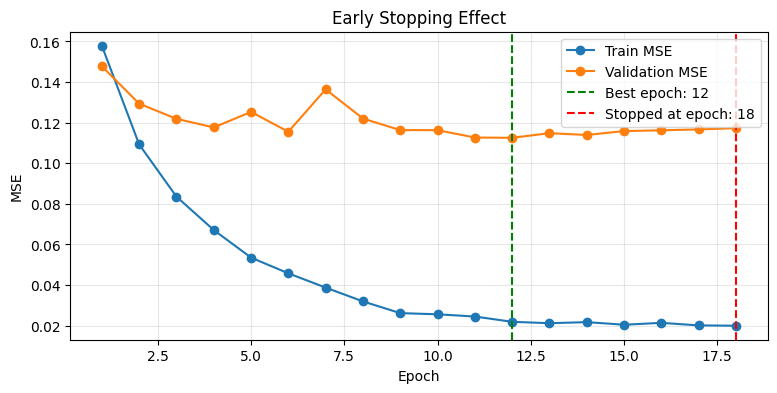

In [42]:
epochs_range = range(1, len(ultimate_history["train_mse"]) + 1)

plt.figure(figsize=(9, 4))
plt.plot(epochs_range, ultimate_history["train_mse"], marker="o", label="Train MSE")
plt.plot(epochs_range, ultimate_history["val_mse"], marker="o", label="Validation MSE")

plt.axvline(
    ultimate_history["best_epoch"],
    color="green",
    linestyle="--",
    label=f"Best epoch: {ultimate_history['best_epoch']}"
)

plt.axvline(
    ultimate_history["stopped_epoch"],
    color="red",
    linestyle="--",
    label=f"Stopped at epoch: {ultimate_history['stopped_epoch']}"
)

plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Early Stopping Effect")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


#### What the early stopping graph shows

The best validation MSE is 0.1125 at epoch 12. Training continues for six more epochs, but no later validation score is better. At epoch 18, training MSE has fallen to 0.0199 while validation MSE is 0.1173. The model fits the training data a little better, but that has not improved validation.

With patience set to six, early stopping ends training at epoch 18 instead of the maximum of 25. We avoid seven additional epochs and restore the weights from epoch 12 rather than keeping those from epoch 18.

This responds to a limitation of our earlier fixed training budgets. We no longer need to guess one exact epoch in advance, although patience is still a hyperparameter that we chose ourselves. The model can also start overfitting before early stopping is triggered, as the separation between the curves suggests.

### 4.5. Learning rate scheduler

We plot the learning rates used by layer4 and the output layer during each epoch. The logarithmic vertical scale makes their changes visible even though their starting values differ by a factor of ten.


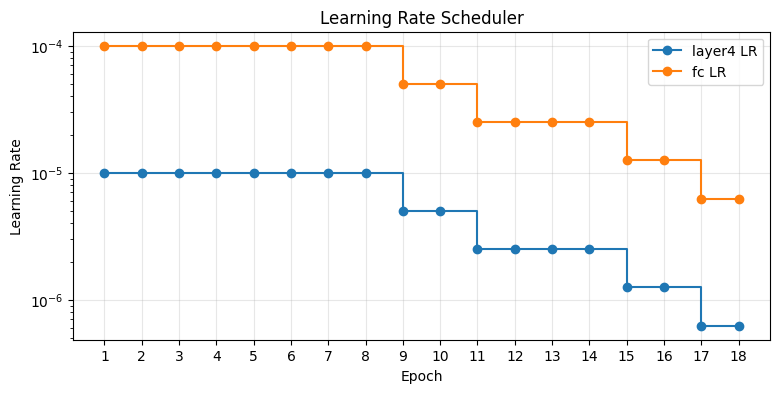

Epochs,layer4 LR,fc LR,Change
1–8,0.000010000,0.000100000,Initial
9–10,0.000005000,0.000050000,÷ 2
11–14,0.000002500,0.000025000,÷ 2
15–16,0.000001250,0.000012500,÷ 2
17–18,0.000000625,0.000006250,÷ 2


In [43]:

# Graph
epochs_range = range(1, len(ultimate_history["lr_fc"]) + 1)

plt.figure(figsize=(9, 4))

plt.plot(
    epochs_range, ultimate_history["lr_layer4"],
    marker="o", drawstyle="steps-post", label="layer4 LR"
)
plt.plot(
    epochs_range, ultimate_history["lr_fc"],
    marker="o", drawstyle="steps-post", label="fc LR"
)

plt.xlabel("Epoch")
plt.ylabel("Learning Rate")
plt.title("Learning Rate Scheduler")
plt.yscale("log")
plt.xticks(list(epochs_range))
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


# Tabulate
lr_fc = ultimate_history["lr_fc"]
lr_layer4 = ultimate_history["lr_layer4"]

changes = [i for i in range(len(lr_fc))
           if i == 0 or lr_fc[i] != lr_fc[i - 1]]

rows = []

for j, i in enumerate(changes):
    end = changes[j + 1] if j + 1 < len(changes) else len(lr_fc)

    rows.append({
        "Epochs": f"{i + 1}–{end}",
        "layer4 LR": lr_layer4[i],
        "fc LR": lr_fc[i],
        "Change": "Initial" if j == 0 else f"÷ {lr_fc[i - 1] / lr_fc[i]:g}"
    })

lr_table = pd.DataFrame(rows)

display(lr_table.style.format({
    "layer4 LR": "{:.9f}",
    "fc LR": "{:.9f}"
}).hide(axis="index"))



#### What the learning rate graph shows

Both learning rates are halved several times, with the new values first used at epochs 9, 11, 15 and 17. These reductions follow periods when validation does not improve enough for the scheduler. Unlike early stopping, the scheduler does not end training. It allows the optimizer to continue with smaller updates.

We can see that the mechanism really acts during our run. We cannot conclude from this graph alone that every reduction improved performance. Validation still fluctuates, and the best checkpoint is reached at epoch 12. To measure the scheduler's contribution on its own, we would need a comparable run without it.

Weight decay was also active throughout the experiment. Since we did not compare it with a run without weight decay, we do not include a graph pretending to measure its effect. The final comparison evaluates the full training setup, not the separate impact of each improvement.


In [44]:
ultimate_model_path = resnet_models_dir / "resnet18_ultimate_best.pth"
torch.save(ultimate_model.state_dict(), ultimate_model_path)


### 4.7. Final test evaluation

We evaluate the model on the same test images used for the previous milestones. The weights come from epoch 12, which gave the lowest validation MSE, rather than epoch 18 when training stopped.


In [45]:
ultimate_model.eval()
ultimate_test_loss = 0.0

with torch.no_grad():
    for images, mos in test_loader_tl:
        images = images.to(device)
        mos = mos.to(device).float().view(-1)

        predictions = ultimate_model(images).squeeze(1)
        loss = ultimate_criterion(predictions, mos)
        ultimate_test_loss += loss.item() * images.size(0)

ultimate_test_mse = ultimate_test_loss / len(transfer_test)
ultimate_test_rmse = ultimate_test_mse ** 0.5

print(f"Ultimate Model Test MSE: {ultimate_test_mse:.4f}")
print(f"Ultimate Model Test RMSE: {ultimate_test_rmse:.4f}")


Ultimate Model Test MSE: 0.1175
Ultimate Model Test RMSE: 0.3428


### 4.8. Comparison with Fine-Tuning

The table and graphs below compare our earlier Fine-Tuning model with the Ultimate Model. Both start from the same Feature Extraction checkpoint and use the same data split. Both graphs use the same zoomed vertical scale to make the small numerical differences easier to see. Because the axis does not start at zero, the bar heights should be interpreted using the MSE values rather than their apparent proportions.

For the Ultimate Model, we combined three improvements with early stopping, a learning rate scheduler and weight decay using AdamW. Since we introduced these changes together, we cannot determine how much each technique contributed to the final result.

To better understand their individual impact, we could conduct further experiments by introducing each technique separately while keeping the other training settings unchanged. This would help us identify which improvements are actually beneficial for our model.

,Model,Validation MSE,Test MSE,Test RMSE
0,ResNet-18 Fine-Tuning,0.1148,0.1187,0.3445
1,Ultimate Model,0.1125,0.1175,0.3428


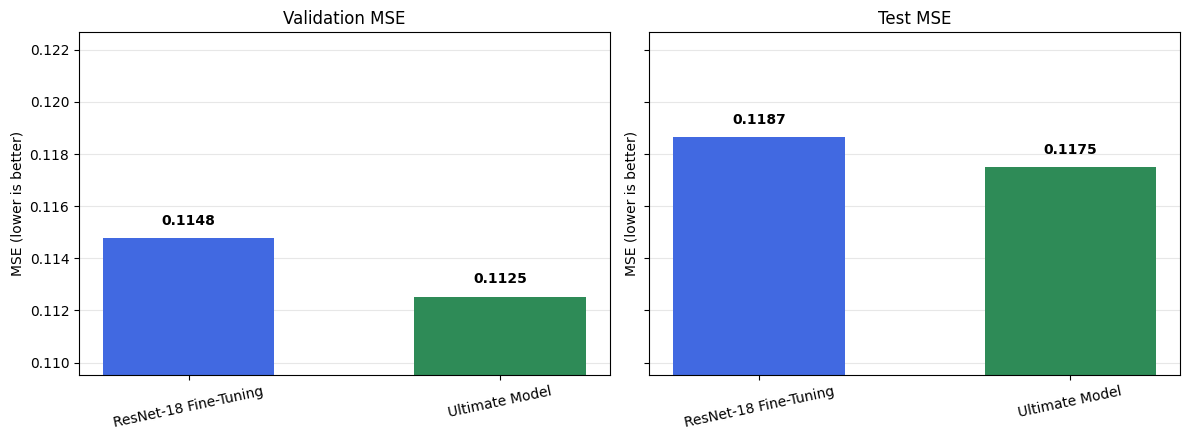

In [46]:

ultimate_comparison = pd.DataFrame({
    "Model": ["ResNet-18 Fine-Tuning", "Ultimate Model"],
    "Validation MSE": [resnet_best_val_mse, min(ultimate_history["val_mse"])],
    "Test MSE": [resnet_test_mse, ultimate_test_mse],
    "Test RMSE": [resnet_test_rmse, ultimate_test_rmse],
})
display(ultimate_comparison.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)

models = ultimate_comparison["Model"]
colors = ["royalblue", "seagreen"]

# Same zoomed scale for both graphs
y_min = ultimate_comparison[["Validation MSE", "Test MSE"]].min().min() - 0.003
y_max = ultimate_comparison[["Validation MSE", "Test MSE"]].max().max() + 0.004

for ax, metric in zip(axes, ["Validation MSE", "Test MSE"]):
    bars = ax.bar(
        models,
        ultimate_comparison[metric],
        color=colors,
        width=0.55
    )

    ax.set_title(metric)
    ax.set_ylabel("MSE (lower is better)")
    ax.tick_params(axis="x", labelrotation=12)
    ax.set_ylim(y_min, y_max)
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)

    for bar in bars:
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.0005,
            f"{bar.get_height():.4f}",
            ha="center",
            fontweight="bold"
        )

plt.tight_layout()
plt.show()


### 4.9. What we learned

Our final model reaches 0.1125 validation MSE and 0.1175 test MSE. The previous Fine-Tuning model reaches 0.1148 and 0.1187. The test MSE improvement is about 1%, which is relatively small in this experiment.

We do not want to make this gain sound larger than it is. The more visible results are in the training curves. Early stopping prevents the run from continuing to epoch 25, and the scheduler adjusts the learning rates several times as validation fluctuates. These mechanisms make the procedure more responsive to the model's actual behavior.

This does not prove that each technique improved test performance. In a different training run or with a model that overfits more strongly, their effects could be larger or smaller. We would need separate controlled comparisons and additional seeds to find out.


## 5. Overall conclusion

Our first CNN performs better than a model that always predicts the average MOS. However, its validation curve improves slowly after the first few epochs, and several individual predictions still have large errors. It gives us a useful baseline rather than a final solution.

Our LSTM improves steadily on the training set, but validation barely progresses after the early epochs. The gap between the curves grows, which suggests overfitting in our configuration. Its test MSE is also worse than the CNN's. We think the sequence of image rows makes spatial patterns harder to exploit, but our experiment does not show that LSTMs are always worse for image quality assessment.

ResNet gives the largest improvement in our project. We first reuse pretrained features and then adapt the final block to the MOS prediction task. Fine-Tuning reduces validation error significantly, but its training MSE keeps falling while validation fluctuates. This makes checkpoint selection important even with a more capable model.

The last milestone addresses the problem of deciding how long and how aggressively to train. Early stopping ends training after six epochs without a new best validation score. The scheduler reduces the learning rates when progress slows, while weight decay provides additional regularization. Their combined test gain is only about 1% compared with our earlier Fine-Tuning result. We can observe the stopping and learning rate adjustments directly, but we cannot identify the contribution of each technique separately.

Beyond the results themselves, this project helped us develop a more critical approach to our experiments. We learned to look at the full training process rather than focusing only on the final scores, and to distinguish what our results actually show from what we can only assume. It also made us more careful when comparing models and interpreting small improvements. Each experiment gave us something to learn, even when the results were below our expectations.

If we had more time, we would explore hyperparameter tuning more thoroughly, especially the learning rates, number of epochs and regularization settings. Our goal would be to find a better balance between model performance and generalization, rather than simply reducing the training loss. We could also repeat experiments with different seeds to check the stability of our results and better understand the contribution of each training strategy. Throughout this TP, we focused more on understanding and applying the different Deep Learning concepts than on achieving the best possible performance. Being able to explain our choices, interpret the results and identify the limitations of our models was the most important part of our work.
